**Universidad Internacional de La Rioja (UNIR) - Máster Universitario en Inteligencia Artificial - Procesamiento del Lenguaje Natural** 

***
Datos del alumno (Nombre y Apellidos): Daniel Godoy Velles

Fecha: 23/20/2026
***

<span style="font-size: 20pt; font-weight: bold; color: #0098cd;">Trabajo: Caracterización de textos</span>

**Objetivos** 

Con esta actividad se tratará de que el alumno se familiarice con el manejo de la librería spacy, así como con los conceptos básicos de manejo de las técnicas NER

**Descripción**

En esta actividad debes procesar de forma automática un texto en lenguaje natural para detectar características básicas en el mismo, y para identificar y etiquetar las ocurrencias de conceptos como localización, moneda, empresas, etc.

En la primera parte del ejercicio se proporciona un código fuente a través del cual se lee un archivo de texto y se realiza un preprocesado del mismo. En esta parte el alumno tan sólo debe ejecutar y entender el código proporcionado.

En la segunda parte del ejercicio se plantean una serie de preguntas que deben ser respondidas por el alumno. Cada pregunta deberá responderse con un fragmento de código fuente que esté acompañado de la explicación correspondiente. Para elaborar el código solicitado, el alumno deberá visitar la documentación de la librería spacy, cuyos enlaces se proporcionarán donde corresponda.

# Parte 1: carga y preprocesamiento del texto a analizar

Observa las diferentes librerías que se están importando.

In [2]:
import csv
import re
from collections import Counter
from collections.abc import Callable
from pathlib import Path
from typing import cast

import es_core_news_md
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import spacy
from spacy import displacy
from spacy.tokens import Doc, Token

El siguiente código simplemente carga y preprocesa el texto. Para ello, lo primero que hace es cargar un modelo de lenguaje previamente entrenado. En este caso, se utiliza <i>es_core_news_md</i>: 

https://spacy.io/models/es#es_core_news_md


In [3]:
nlp = es_core_news_md.load()

El objeto <i>nlp</i> permite utilizar el modelo de lenguaje cargado, de forma que se puede procesar un texto y obtenerlo en su versión preprocesada. Así, nos permite realizar las diferentes tareas. En este caso, vamos a utilizar el pipeline para hacer un preprocesamiento básico, que consiste en tokenizar el texto.

In [4]:
DATA = Path("../data")

filename = DATA / "02Dataset_anonimizado.csv"
data = pd.read_csv(filename, sep=";", encoding="latin-1")
data.head()

/tmp/ipykernel_331995/378802008.py:4: DtypeWarning: Columns (6: TIPO DE ODIO, 7: TONO HUMORISTICO, 8: MODIFICADOR) have mixed types. Specify dtype option on import or set low_memory=False.
  data = pd.read_csv(filename, sep=";", encoding="latin-1")


,MEDIO,SOPORTE,URL,TIPO DE MENSAJE,CONTENIDO A ANALIZAR,INTENSIDAD,TIPO DE ODIO,TONO HUMORISTICO,MODIFICADOR,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15
0,EL PAÍS,WEB,URL_a4d7efc0,COMENTARIO,el barí§a nunca acaeza ante un segundo b ni an...,3.0,Otros,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,EL PAÍS,WEB,URL_a4d7efc0,COMENTARIO,el real madrid ha puesto punto y final a su an...,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,EL PAÍS,WEB,URL_54312d9e,COMENTARIO,cristina cifuentes podrí­a haber sido la presi...,3.0,Ideológico,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,EL PAÍS,WEB,URL_54312d9e,COMENTARIO,habrí­a que reabrir el caso. el supremo se ded...,3.0,Ideológico,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,EL PAÍS,WEB,URL_54312d9e,COMENTARIO,me parece un poco exagerado pedir más de tres ...,3.0,Ideológico,Si,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Arreglar los carácteres extraños

In [5]:
replacements = {

    # letras acentuadas

    "Ã¡": "á", "Ã©": "é", "Ã­": "í", "Ã³": "ó", "Ãº": "ú",

    "Ã": "Á", "Ã‰": "É", "Ã": "Í", "Ã“": "Ó", "Ãš": "Ú",

 # ñ / ç

    "Ã±": "ñ", "Ã‘": "Ñ",

    "í±": "ñ", 

    "í§": "ç", "Ã§": "ç",

 # diéresis

    "Ã¼": "ü", "Ã": "Ü",

    "í¼": "ü",

 # comillas mal decodificadas

    "â€œ": "“", "â€": "”", "â€˜": "‘", "â€™": "’",

 

    # guiones, puntos y comillas ascii dañadas

    "â€“": "–",  # dash

    "â€”": "—",  # em dash

    "â€": "‘",

    "â€": "”",   # frecuencia alta en texto dañado

    "â€¦": "…",  # ellipsis

 # signos ¿ ¡

    "Â¿": "¿", "Â¡": "¡",

    "Ã¿": "¿",

# errores comunes de doble decodificación

    "Ã¢ÂÂ": "'",     # rara, pero segura

    "Ã¢ÂÂ,": ",",

    "Ã¢ÂÂ.": ".",

    "Ã¢ÂÂ¦": "…",

    "Ã¢ÂÂ ": " ",

    "ÃÂ": "-",

}

def fix_mojibake(s):

    # Función de pandas para detectar NAN

    if pd.isna(s):

        return ""

    for bad, good in replacements.items():

        s = s.replace(bad, good)

    return s

# La manera más rápida de ejecutar la función es de forma vectorizada

data["CONTENIDO A ANALIZAR"] = [fix_mojibake(t) for t in data["CONTENIDO A ANALIZAR"].values]
data["CONTENIDO A ANALIZAR"].head()

0    el barça nunca acaeza ante un segundo b ni ant...
1    el real madrid ha puesto punto y final a su an...
2    cristina cifuentes podrí­a haber sido la presi...
3    habrí­a que reabrir el caso. el supremo se ded...
4    me parece un poco exagerado pedir más de tres ...
Name: CONTENIDO A ANALIZAR, dtype: str

El código anterior carga el archivo CSV (opcionalmente con un límite de líneas a leer) y genera la variable <i>data</i>, que contiene un Dataframe (https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.html) con los datos leídos del CSV.

Te vendrá bien conocer la siguiente documentación:
<ul>
    <li>https://spacy.io/api/doc</li>
    <li>https://spacy.io/api/token</li>
    <li>https://spacy.io/api/morphology#morphanalysis</li>
</ul>

### Playground

Utiliza este espacio para hacer pruebas y ensayos con las variables generadas con el código previo. A modo de ejemplo, se ofrece código que realiza las siguientes tareas: 


- leer un número dado de líneas del Dataframe y generar dos listas con los valores (se pueden leer directamente del DataFrame, se muestra el ejemplo como una opción más)
- procesar el texto de cada comentario


Para procesarlo, hay utilizar el objeto <i>nlp</i> y así obtener objetos de la clase <i>Doc</i> (https://spacy.io/api/doc)

Visita la documentación de dicha clase y experimenta probando las diferentes funciones y atributos 

Antes de realizar nada, es necesario ver qué parte del DataFrame tiene información relevante. 

In [6]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 575029 entries, 0 to 575028
Data columns (total 16 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   MEDIO                 575029 non-null  str    
 1   SOPORTE               574896 non-null  str    
 2   URL                   574773 non-null  str    
 3   TIPO DE MENSAJE       574767 non-null  str    
 4   CONTENIDO A ANALIZAR  575029 non-null  str    
 5   INTENSIDAD            574630 non-null  float64
 6   TIPO DE ODIO          12293 non-null   str    
 7   TONO HUMORISTICO      143 non-null     str    
 8   MODIFICADOR           350 non-null     str    
 9   Unnamed: 9            0 non-null       float64
 10  Unnamed: 10           0 non-null       float64
 11  Unnamed: 11           0 non-null       float64
 12  Unnamed: 12           0 non-null       float64
 13  Unnamed: 13           0 non-null       float64
 14  Unnamed: 14           0 non-null       float64
 15  Unnamed: 15

Esto muestra que desde la columna 9 hasta la 15 no existe información, puesto que todos los valores son nulos. Por tanto, vamos a eliminar de antemano todas las columnas cuyos valores sean todos nulos/nan.

In [7]:
# eliminar todas las columnas que no aportan información

# forma 1
delete = data.columns[data.isna().all()]
data = data.drop(columns=delete)

# forma 2
data = data.dropna(axis=1, how="all")

data.head()

,MEDIO,SOPORTE,URL,TIPO DE MENSAJE,CONTENIDO A ANALIZAR,INTENSIDAD,TIPO DE ODIO,TONO HUMORISTICO,MODIFICADOR
0,EL PAÍS,WEB,URL_a4d7efc0,COMENTARIO,el barça nunca acaeza ante un segundo b ni ant...,3.0,Otros,NaN,NaN
1,EL PAÍS,WEB,URL_a4d7efc0,COMENTARIO,el real madrid ha puesto punto y final a su an...,0.0,NaN,NaN,NaN
2,EL PAÍS,WEB,URL_54312d9e,COMENTARIO,cristina cifuentes podrí­a haber sido la presi...,3.0,Ideológico,NaN,NaN
3,EL PAÍS,WEB,URL_54312d9e,COMENTARIO,habrí­a que reabrir el caso. el supremo se ded...,3.0,Ideológico,NaN,NaN
4,EL PAÍS,WEB,URL_54312d9e,COMENTARIO,me parece un poco exagerado pedir más de tres ...,3.0,Ideológico,Si,NaN


### ¿Existe correspondencia total entre Tipo de Odio = Nan e intensidad 0.0?
Al observar los datos podemos ver que "Tipo de Odio" tiene muchos nulos mientras que "Intensidad" no. Esto puede ser porque se codifique la ausencia de odio como Tipo de Odio nulo/nan. Para ello veamos si existe correspondencia total o no. En caso de que sí, podemos decir con seguridad que Tipo de Odio Nulo/Nan tiene como signficado únicamente "no tiene odio".

In [8]:
int0 = data["INTENSIDAD"] == 0.0
odio_na = data["TIPO DE ODIO"].isna()

int0_con_tipo = int0 & ~odio_na
tipo_na_con_int = ~int0 & odio_na

if int0_con_tipo.any() or tipo_na_con_int.any():
    print("No hay correspondencia:")
    print(f"  - {int0_con_tipo.sum()} casos con intensidad 0.0 y tipo de odio no NaN")
    print(f"  - {tipo_na_con_int.sum()} casos con tipo de odio NaN e intensidad > 0")
else:
    print("Correspondencia total: intensidad 0.0 <-> tipo de odio Nan")

# Tabla de contingencia
pd.crosstab(
    int0, odio_na, rownames=["INTENSIDAD == 0"], colnames=["TIPO DE ODIO es NaN"]
)

No hay correspondencia:
  - 0 casos con intensidad 0.0 y tipo de odio no NaN
  - 402 casos con tipo de odio NaN e intensidad > 0


TIPO DE ODIO es NaN,False,True
INTENSIDAD == 0,,
False,12293,402
True,0,562334


No existe correspondencia total, por lo que no podemos decir que Tipo de Odio = Nan signifique que no existe odio. Para poder suponer la correspondencia total, vamos a eliminar todos los casos que incumplen esta para el análisis. De esta manera lo simplificamos las fases posteriores.

In [9]:
# todos los que no cumplen (intensidad != 0 y t. odio = Nan) a la vez se quedan
data = data[~tipo_na_con_int]

int0 = data["INTENSIDAD"] == 0.0
odio_na = data["TIPO DE ODIO"].isna()

int0_con_tipo = int0 & ~odio_na
tipo_na_con_int = ~int0 & odio_na

if int0_con_tipo.any() or tipo_na_con_int.any():
    print("No hay correspondencia:")
    print(f"  - {int0_con_tipo.sum()} casos con intensidad 0.0 y tipo de odio no NaN")
    print(f"  - {tipo_na_con_int.sum()} casos con tipo de odio NaN e intensidad > 0")
else:
    print("Correspondencia total: intensidad 0.0 <-> tipo de odio Nan")

# Tabla de contingencia
pd.crosstab(
    int0, odio_na, rownames=["INTENSIDAD == 0"], colnames=["TIPO DE ODIO es NaN"]
)


Correspondencia total: intensidad 0.0 <-> tipo de odio Nan


TIPO DE ODIO es NaN,False,True
INTENSIDAD == 0,,
False,12293,0
True,0,562334


### ¿Cómo es la distribución de intensidades?

Valores de intensidad: [0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0]


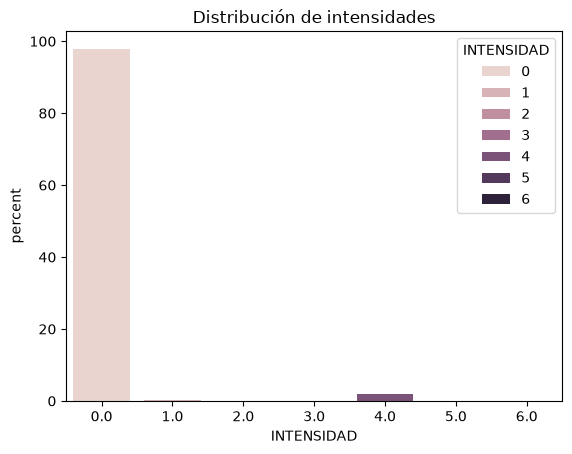

Casos con odio: 12293
Casos sin odio: 562334
Ratio sin odio/odio: 45.7442446921012


In [20]:
print(f"Valores de intensidad: {sorted([float(i) for i in data["INTENSIDAD"].unique()])}")

sns.countplot(data=data, x="INTENSIDAD", hue="INTENSIDAD", stat="percent")
plt.title("Distribución de intensidades")
plt.show()

con_odio = len(data[data["INTENSIDAD"] > 0.0])
sin_odio = len(data[data["INTENSIDAD"] == 0.0])
print(f"Casos con odio: {con_odio}")
print(f"Casos sin odio: {sin_odio}")
print(f"Ratio sin odio/odio: {sin_odio/con_odio}")


Se puede observar que casi todo el dataset consta de casos donde no existe odio: hay casi 46 veces más casos sin odio que con él.

### Aplicación del pipeline nlp de spac.

In [21]:
# # Puedes insertar aquí código de pruebas para experimentar con las diferentes funciones y atributos de 'doc'.
# #print(data["CONTENIDO A ANALIZAR"][1])
# #print(data["INTENSIDAD"][1])
# from spacy.tokens import Doc


# doc: list[Doc] = []
# value = []

# #con el bucle, generamos sendas listas con los comentarios ya parseados y con el valor de intensidad
# for i in range(len(data)):

#     #en un primer paso se parsea el comentario. En el segundo paso se añade el objeto a la lista
#     tmp_doc = nlp(data["CONTENIDO A ANALIZAR"][i])
#     doc.append(tmp_doc)

#     #en un primer paso extrae el valor. En el segundo paso se añade el valor a la lista
#     tmp_value = data["INTENSIDAD"][i]
#     value.append(tmp_value)


# #ejemplo de cómo recorrer un comentario palabra por palabra
# for expr, intensidad in zip(doc, value):
#     end = min(30, len(expr))
#     print(f"({intensidad}): {expr[0:end]}")

<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">Pregunta 1.</span>
<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">¿Cuántos registros contiene el corpus?</span>

In [22]:
sentence_count = len(data)  # igual a lines_number porque es lo que importamos
# n_sentences = data.shape[0] # lo mismo pero se indica explícitamente "el número de filas"
print(sentence_count)

574627


<b>Incluye aquí, debajo de la línea, la explicación de tu respuesta</b>
<hr>

El corpus contiene **574.627 registros**, que es el número de filas del DataFrame `data` (`len(data)`). Este recuento se hace después de eliminar los 402 registros inconsistentes, es decir, los que tienen intensidad mayor que 0 pero no tienen tipo de odio. Sin quitarlos, el CSV tiene 575.029 registros (ver `data.info()`).

<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">Pregunta 2.</span>
<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">¿Cuántas palabras totales hay en los comentarios del corpus?</span>

Puesto que aquí necesitamos ejecutar el pipeline, se escoge reducir el conjunto por limitaciones computacionales. Se selecciona el mismo número de registros de odio y no odio para que todas las siguientes preguntas respondan utilizando grupos balanceados.

Puesto que se pregunta por "Comentarios", se observan los tipos de mensaje.

In [23]:
# analizar si hay más de un tipo de oraciones
print(f"Tipos de mensaje: {list(data["TIPO DE MENSAJE"].unique())}")

Tipos de mensaje: ['COMENTARIO', 'NOTICIA', 'TITULAR NOTICIA', nan]


In [24]:
# se filtra por aquellos que son comentarios
comentarios = data[data["TIPO DE MENSAJE"] == "COMENTARIO"]

# se limitan
MAX_ROWS = 30_000
odio_mask = comentarios["INTENSIDAD"] > 0
odio = comentarios[odio_mask].iloc[:MAX_ROWS//2].copy()
# limitamos el grupo sobremuestreado al submuestreado
no_odio = comentarios[~odio_mask].iloc[:len(odio)].copy()

comentarios = pd.concat([odio, no_odio], ignore_index=True)
print(f"Registros de odio: {len(odio)}")
print(f"Registros de no odio: {len(no_odio)}")

Registros de odio: 10618
Registros de no odio: 10618


In [25]:
# esta forma alternativa permite acelerar el procesado utilizando batches y más cores del procesador.
docs = list(
    nlp.pipe(comentarios["CONTENIDO A ANALIZAR"].astype(str), batch_size=500, n_process=-1)
)
comentarios["doc"] = pd.Series(docs, index=comentarios.index)  # dentro de un series para evitar error de Pylance

In [42]:
word_count = 0
word_set: set[str] = set()
lemma_set: set[str] = set()

doc: Doc  # tipado para intellisense
for doc in comentarios["doc"]:
    for token in doc:
        if not token.is_punct:
            # Sin normalización, lematización, stemming... únicamente se ha tokenizado
            word_count += 1

            # ver si es posible utilizar alguna función o atributo de spacy para el número de palabras.

            # Normalizados a minúscula.
            word_set.add(token.lower_)  # !revisar documentación de Doc
            # Normalizados al lema
            lemma_set.add(token.lemma_)

print(f"Palabras (sin signos de puntuación): {word_count:,}")
print(f"Palabras únicas: {len(word_set):,}")
print(f"Lemas únicos: {len(lemma_set):,}")
print("Conjunto de palabras:", list(word_set)[:10])
print("Conjunto de lemas:", list(lemma_set)[:10])

Palabras (sin signos de puntuación): 389,320
Palabras únicas: 38,243
Lemas únicos: 30,883
Conjunto de palabras: ['viral', 'ü\x82¿estos', 'chaquetero', '2b', '8', 'sinónimo', 'amotinados', 'esquí\xad', 'momia', 'internacionamente']
Conjunto de lemas: ['viral', 'chaquetero', '2b', '8', 'sinónimo', 'momia', 'internacionamente', 'raposa', 'champiño', 'putincracia']


<b>Incluye aquí, debajo de la línea, la explicación de tu respuesta</b>
<hr>
 
Se han identificado los tipos de mensajes disponibles y se ha filtrado por el tipo 'COMENTARIO'. Tras ello, se ha utilizado el análisis anteriormente hecho por es_core_mw para identificar cada una de las palabras existentes. Puesto que este pipeline extrae las palabras y los signos de puntuación como tokens, se excluyen los signos de puntuación y se cuentan cada uno de los tokens restantes para cada comentario.

Además, se ha contado también el número de palabras únicas (normalizando a minúscula) y el número de lemas únicos (extrayendo el lema propuesto por es_core_mw).

<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">Pregunta 3.</span>
<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">¿Cuál el número promedio de palabras en cada comentario?</span>

In [43]:
# Incluye aquí el código generado para poder responder a tu pregunta
mean_words = word_count / len(comentarios)
print(f"Mean: {mean_words:.2f} words/sentence in comments")

Mean: 18.33 words/sentence in comments


<b>Incluye aquí, debajo de la línea, la explicación de tu respuesta</b>
<hr>

El número promedio de palabras por comentario es **18,33**. Se obtiene dividiendo el total de palabras calculado en la pregunta 2 entre el número de comentarios analizados. Por tanto, el promedio corresponde a la muestra equilibrada de odio y no odio, no a todos los comentarios del corpus.

<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">Pregunta 4.</span>
<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">Considerando dos grupos de comentarios (odio y no odio) ¿Cuál el número promedio de palabras en los comentarios de cada grupo?</span>

In [44]:
# Incluye aquí el código generado para poder responder a tu pregunta
print(data["TIPO DE ODIO"].value_counts())
print("\nIntesidades:")
print(sorted(float(i) for i in data["INTENSIDAD"].unique()))

TIPO DE ODIO
Otros                           8997
Ideológico                      1721
Xenofobia                        359
Otros, Misoginia                 264
Otros, Ideológico                194
                                ... 
Otros, Ideológico, Misoginia       1
Otros, Misoginia, Racismo          1
Otros, Xenofobia, Misoginia        1
Otros, Religioso                   1
Otros, Sexual, Ideológico          1
Name: count, Length: 72, dtype: int64

Intesidades:
[0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0]


In [45]:
comentarios["word_count"] = [
    sum(1 for token in doc if not token.is_punct) for doc in comentarios["doc"]
]

mask_no_odio = comentarios["INTENSIDAD"] == 0.0
no_odio = comentarios[mask_no_odio]
odio = comentarios[~mask_no_odio]

print("--------------ODIO------------------")
print(f"Promedio: {sum(odio["word_count"]) / len(odio):.2f}")
print(f"Mediana: {odio["word_count"].median():.2f}")

print("------------NO ODIO-----------------")
print(f"Promedio: {sum(no_odio["word_count"]) / len(no_odio):.2f}")
print(f"Mediana: {no_odio["word_count"].median():.2f}")


--------------ODIO------------------
Promedio: 15.87
Mediana: 10.00
------------NO ODIO-----------------
Promedio: 20.79
Mediana: 12.00


<b>Incluye aquí, debajo de la línea, la explicación de tu respuesta</b>
<hr>
 

Puesto que anteriormente hemos podido confirmar que intensidad 0 significa tipo de odio nulo, podemos dividir utilizando cualquiera de esas dos condiciones. Se elige dividir usando intensidad. Tras ello, se cuenta el número de palabras y se almacena en el DataFrame, con la misma lógica que en la anterior pregunta. Lo siguiente es calcular el promedio de la columna "word_count" para cada grupo.

Se ha decidido observar la mediana para ver si la diferencia de medias es debida al conjunto en sí mismo o a algunos valores anómalos. Puesto que la diferencia en la mediana es bastante menor, probablemente existan algunos (o más) comentarios extremadamente largos en "no odio".

<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">Pregunta 5.</span>
<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">Considerando dos grupos de comentarios (odio y no odio) ¿Cuál es el número promedio de oraciones en los comentarios de cada grupo?</span>

In [46]:
comentarios["CONTENIDO A ANALIZAR"].head()


0    el barça nunca acaeza ante un segundo b ni ant...
1    cristina cifuentes podrí­a haber sido la presi...
2    habrí­a que reabrir el caso. el supremo se ded...
3    me parece un poco exagerado pedir más de tres ...
4    parece que todos los delincuentes niegan las e...
Name: CONTENIDO A ANALIZAR, dtype: str

In [47]:
comentarios_con_puntos = sum(
    [
        1
        for content in comentarios["CONTENIDO A ANALIZAR"]
        if re.search(r"\.", cast(str, content))
    ]
)
print(
    f"Proporción de comentarios con puntos: {comentarios_con_puntos/len(comentarios):.2f}"
)

Proporción de comentarios con puntos: 0.58


Observando el output, se puede ver que existen oraciones sin puntuación. Esto implica que opciones como el sentencizer o cualquiera que utilize puntuación para determinar el inicio o final de una oración pueden no tener suficiente precisión. Esto tiene sentido, pues el corpus pertenece a comentarios en redes sociales, donde es extraño encontrar la escritura correcta del español.

In [48]:
# Incluye aquí el código generado para poder responder a tu pregunta

comentarios["sent_count"] = [
    sum(1 for sent in cast(Doc, doc).sents) for doc in comentarios["doc"]
]
no_odio = comentarios[mask_no_odio]
odio = comentarios[~mask_no_odio]

print(f"Promedio no odio: {sum(no_odio["sent_count"]) / len(no_odio):.2f}")
print(f"Promedio odio: {sum(odio["sent_count"]) / len(odio):.2f}")

Promedio no odio: 1.74
Promedio odio: 1.58


<b>Incluye aquí, debajo de la línea, la explicación de tu respuesta</b>
<hr>
Se ha realizado el análisis utilizando el parser del pipeline, en particular la función `sents`, por la propia naturaleza del corpus. Como se ha indicado antes, existen muchas oraciones sin punto, lo que implica que enfoques que usan el punto (o la puntuación en general) para determinar el número de oraciones podrían ser poco efectivos. Ya de entrada, el 42% de los datos no posee puntos, lo que descarta la detección correcta de un gran porcentaje del corpus.

Tal como se indica en su propia documentación: " If your texts are closer to general-purpose news or web text, this should work well out-of-the-box with spaCy’s provided trained pipelines.", por lo que se utilizará para ello. No obstante, también se indica que para redes sociales sería conveniente un entrenamiento personalizado.

[Parser](https://spacy.io/usage/linguistic-features#sbd)

<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">Pregunta 6.</span>
<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">Considerando dos grupos de comentarios (odio y no odio) ¿Cuál es el porcentaje de comentarios que contienen entidades NER en cada grupo?</span>

In [49]:
# Incluye aquí el código generado para poder responder a tu pregunta

comentarios["entity_count"] = [sum(1 for ent in doc.ents) for doc in comentarios["doc"]]
no_odio = comentarios[mask_no_odio]
odio = comentarios[~mask_no_odio]

print(
    f"Contienen entidades (no odio): {sum(no_odio["entity_count"] > 0) / len(no_odio) * 100:.2f}%"
)
print(
    f"Contienen entidades (odio): {sum(odio["entity_count"] > 0) / len(odio) * 100:.2f}%"
)

Contienen entidades (no odio): 32.41%
Contienen entidades (odio): 35.52%


In [50]:
max_entities = comentarios.loc[comentarios["entity_count"] == 5, "doc"]
displacy.render(max_entities.iloc[0], style="ent")

<b>Incluye aquí, debajo de la línea, la explicación de tu respuesta</b>
<hr>
Se ha utilizado Doc.ents para la consecución de este objetivo por ser la salida de la última fase del pipeline es_core_news_md. Este atributo devuelve todas las entidades que posee un Doc. Por tanto, se calcula qué contenidos tienen una entidad o más y se calcula el porcentaje de comentarios con entidades para las segmentaciones odio/no odio.


[Displacy](https://spacy.io/usage/visualizers)
[Named Entity Recognition](https://spacy.io/usage/linguistic-features#named-entities)   

<span style="font-size: 16pt; font-weight: bold; color: #0098cd;">Plantea tus propias preguntas</span>

<span><b>Plantea al menos 4 características</b> del texto cuyo análisis permita una caracterización completa del texto. Puedes utilizar recomendaciones proporcionadas por la IA Generativa, si así lo deseas. Para cada una de las características planteadas, obtén valores separados para los grupos ODIO/NO-ODIO.</span>

<span>En la explicación aportada, deberás <b>explicar el significado de la característica planteada</b> así como la importancia de ésta en la caracterización del texto.</span>

<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">Característica adicional 1.</span>


<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">Palabras más frecuentes</span>

In [51]:
grupos = {
    "no odio": comentarios[comentarios["INTENSIDAD"] == 0.0],
    "odio": comentarios[comentarios["INTENSIDAD"] > 0.0],
}

valid_word = lambda t: t.is_alpha and not t.is_stop and len(t) > 1

filas = []

for group, df_group in grupos.items():
    word_counter = Counter()
    for doc in df_group["doc"]:
        word_counter.update(token.norm_ for token in doc if valid_word(token))

    total = word_counter.total()
    filas.extend(
        [(group, word, count, count / total * 100) for word, count in word_counter.most_common()]
    )

df_words = pd.DataFrame(filas, columns=["group", "word", "count", "pct"])
df_words["pct_acum"] = df_words.groupby("group")["pct"].cumsum()

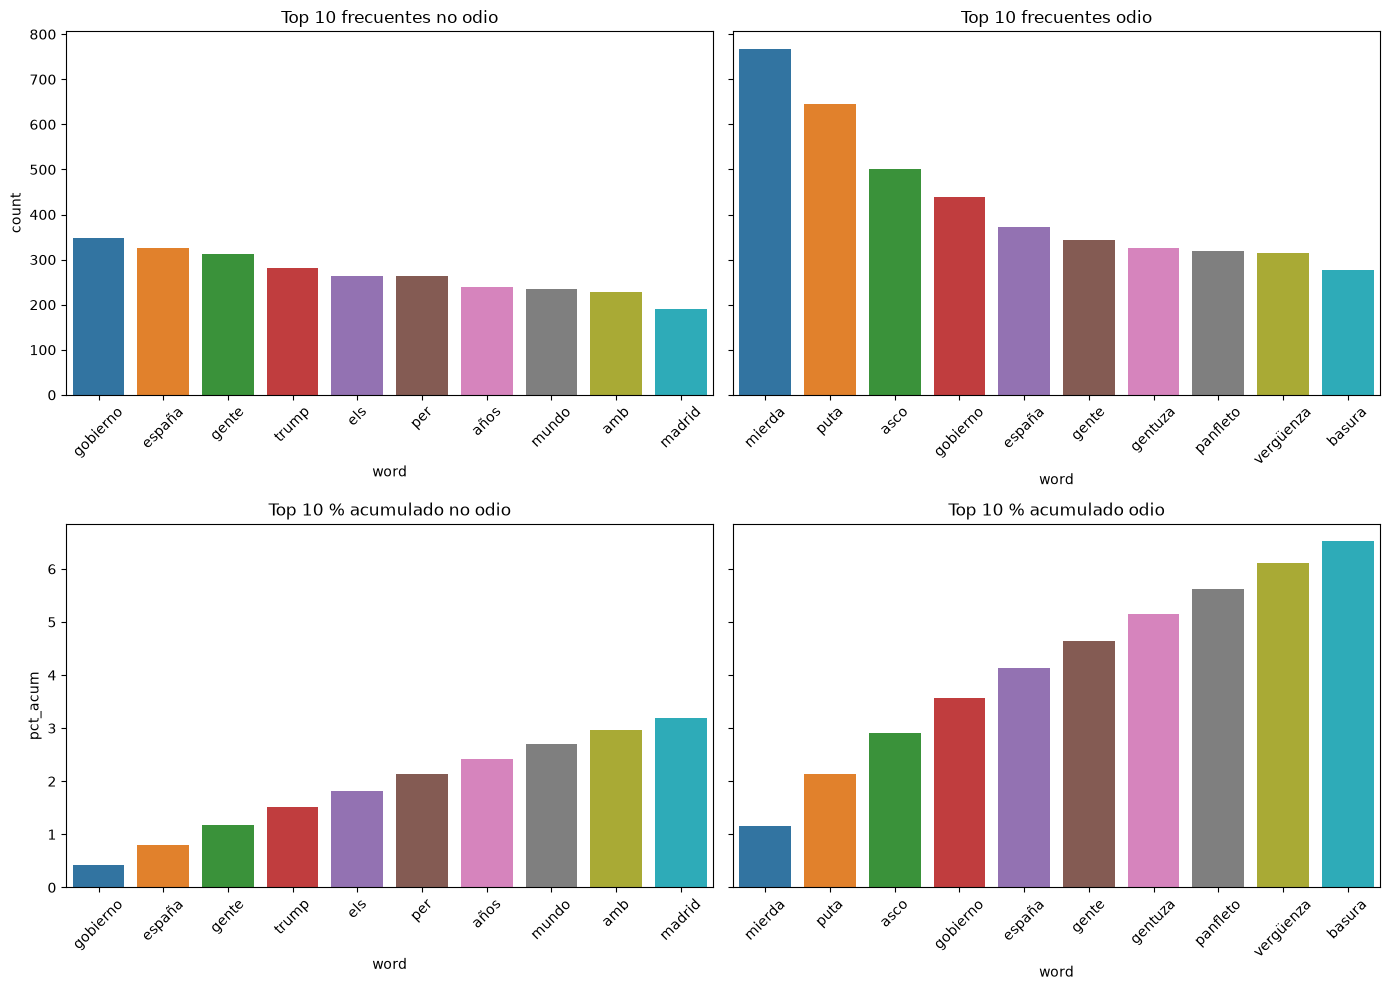

In [52]:
df_top10 = df_words.sort_values("count", ascending=False).groupby("group").head(10)

fig, axes = plt.subplots(2, 2, sharey="row", figsize=(14, 10))
for row, col in zip(axes, ("count", "pct_acum")):
    for group, ax in zip(grupos.keys(), row):
        mask = df_top10["group"] == group
        sns.barplot(data=df_top10.loc[mask], hue="word", x="word", y=col, ax=ax)
        ax.set_title(f"Top 10 frecuentes {group}" if col == "count" else f"Top 10 % acumulado {group}")
        ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

<b>Incluye aquí, debajo de la línea, la explicación de la característica propuesta y su motivación. Incluye también una explicación del código fuente aportado.</b>
<hr>

**Qué mide y por qué**

Mide qué palabras con contenido son las más frecuentes en los comentarios de cada grupo (odio y no odio). La motivación es que el vocabulario es la señal más directa de cómo se expresa un mensaje. Si los comentarios con odio usan un léxico propio, las palabras más usadas deberían reflejarlo. Por tanto, ese léxico podría servir después como rasgo para un clasificador.

**Código**

Para cada grupo se recorren los `doc` y se cuentan con un `Counter` los tokens que son alfabéticos, no son palabras vacías (`is_stop`) y tienen más de una letra, usando su forma normalizada (`token.norm_`). Se descartan las palabras vacías porque, si no, dominarían el recuento (*de*, *que*, *el*...) y no dirían nada del contenido. Se utiliza la forma normalizada para no contar por separado "Hola" y "hola". Con los conteos se calcula el porcentaje de cada palabra sobre el total de palabras válidas del grupo y su acumulado (`cumsum`), y se muestran las 10 más frecuentes de cada grupo, en número de apariciones y en porcentaje acumulado.

**Resultados**

- En el top 10 de **odio** aparecen *mierda*, *puta*, *asco*, *gentuza*, *panfleto*, *vergüenza* y *basura*, que son palabras con una connotación claramente negativa. Las dos más frecuentes, *mierda* y *puta*, superan las 600 apariciones cada una.
- En el top 10 de **no odio** no aparece ninguna palabra de ese estilo. Son sobre todo palabras neutras o temáticas: *gobierno*, *España*, *gente*, *Trump*, *años*, *mundo* y *Madrid*.
- *Gobierno*, *España* y *gente* están en los dos grupos.
- Las 10 palabras más frecuentes de odio suman en torno al 6,5 % de las palabras del grupo, frente a un 3,2 % en no odio. Por tanto, parece que el vocabulario de odio está más concentrado en menos palabras.

Esto sugiere que contar palabras con connotación negativa permitiría discernir entre ambos grupos.

**Limitaciones**

- Cuenta palabras sueltas y no entiende el contexto: *no es una mierda* o un uso irónico cuentan igual que un insulto, y tampoco recoge matices finos como el tipo de expresión o el estilo de quien escribe.
- Solo se han mirado las 10 palabras más frecuentes. Lo cual no es una medida muy robusta.
- En no odio aparecen *els*, *per* y *amb*, que son catalán. La lista de palabras vacías del modelo es de español, así que esos comentarios no se filtran como el resto.


<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">Característica adicional 2.</span>


<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">Énfasis expresivo (signos de exclamación e interrogación)</span>

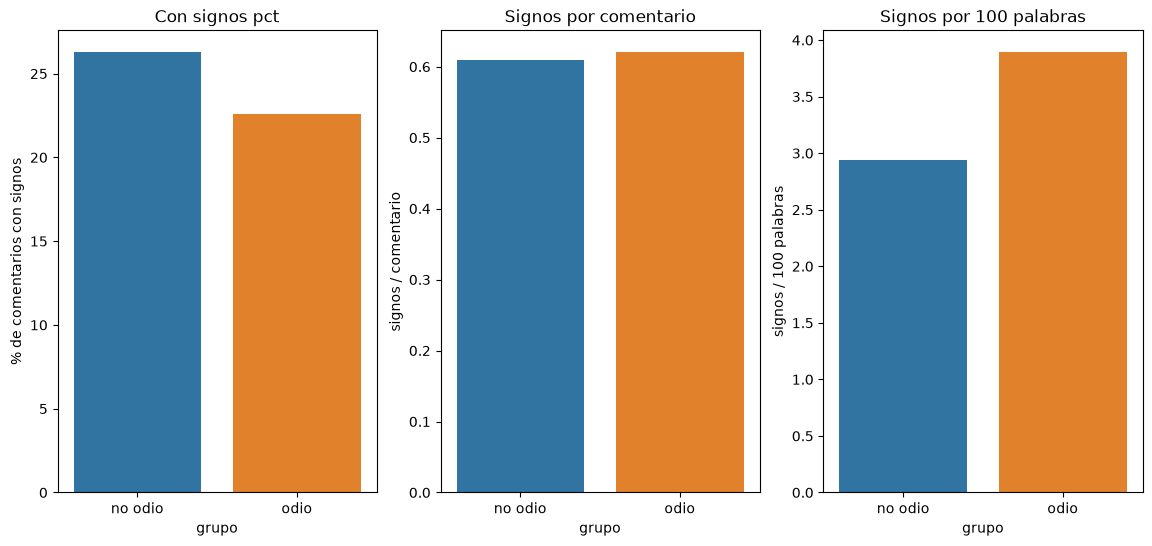

,con_signos_pct,signos_por_comentario,signos_por_100_palabras
grupo,,,
no odio,26.26,0.61,2.94
odio,22.58,0.62,3.89


In [53]:
# signos que marcan énfasis o tono expresivo
SIGNOS = re.compile(r"[!¡?¿]")

textos = comentarios["CONTENIDO A ANALIZAR"]
comentarios["n_signos"] = textos.map(lambda texto: len(SIGNOS.findall(texto))) # type: ignore
comentarios["grupo"] = np.where(comentarios["INTENSIDAD"] > 0.0, "odio", "no odio")

por_grupo = comentarios.groupby("grupo")
df_enfasis = pd.DataFrame(
    {
        # % de comentarios con al menos un signo
        "con_signos_pct": por_grupo["n_signos"].apply(lambda s: (s > 0).mean() * 100),
        # signos por comentario (media)
        "signos_por_comentario": por_grupo["n_signos"].mean(),
        # signos por cada 100 palabras: corrige que los comentarios de odio son más cortos
        "signos_por_100_palabras": por_grupo["n_signos"].sum()
        / por_grupo["word_count"].sum()
        * 100,
    }
).round(2)

medida_col = {
    "con_signos_pct": "% de comentarios con signos",
    "signos_por_comentario": "signos / comentario",
    "signos_por_100_palabras": "signos / 100 palabras"
}

fig, axes = plt.subplots(1, len(df_enfasis.columns), figsize=(14, 2 * len(df_enfasis.columns)))
for col, ax in zip(df_enfasis.columns, axes):
    sns.barplot(
        data=df_enfasis.reset_index(), x="grupo", y=col, hue="grupo", ax=ax
    )
    ax.set_title(col.replace("_", " ").capitalize())
    ax.set_ylabel(medida_col[col])
    
plt.show()

df_enfasis

 <b>Incluye aquí, debajo de la línea, la explicación de la característica propuesta y su motivación. Incluye también una explicación del código fuente aportado.</b>
<hr>

**Qué mide y por qué**

Mide cuánto énfasis expresivo hay en un comentario, a través de los signos de exclamación e interrogación (`!`, `¡`, `?`, `¿`). Estos signos suelen acompañar a mensajes escritos con carga emocional: enfado, indignación, ironía o interpelación directa al lector. Por eso son un buen candidato para caracterizar el tono de los comentarios con odio frente a los que no lo tienen.

**Código**

Con una expresión regular sobre el texto original se cuentan los signos de cada comentario (`n_signos`). Se usa el texto y no los tokens porque el tokenizador de spaCy no siempre separa bein los signos. Para el número de palabras se reutiliza la columna `word_count` (tokens que no son puntuación). Después, por grupo, se calculan tres medidas: 
- el porcentaje de comentarios con al menos un signo, 
- la media de signos por comentario y 
- los signos por cada 100 palabras. 

La última cuenta la densidad de signos de puntuación porque contar signos sin tener en cuenta la longitud favorece a los textos largos.

**Resultados**

Los resultados son mixtos. En odio hay menos comentarios con algún signo y la media por comentario es casi igual, pero por cada 100 palabras hay un 32 % más de signos. Una posible hipótesis es que los comentarios de odio son breves pero más cargados de énfasis cuando lo usan.

La diferencia es moderada, por lo que esta característica por sí sola discrimina poco entre odio y no odio, aunque la densidad por palabra podría aportar como rasgo complementario.

**Limitaciones**

Cada signo cuenta por separado, así que `¡hola!` suma 2.Es decir, dependería de que las personas en un estado de irascibilidad escribieran con la misma corrección que sin este estado. Los signos y las palabras salen de fuentes distintas (el texto original y los tokens de spaCy), de modo que la densidad por 100 palabras depende de la precisión de spaCy. 


<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">Característica adicional 3.</span>


<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">Frecuencia de cada tipo de palabra (UPOS)</span>

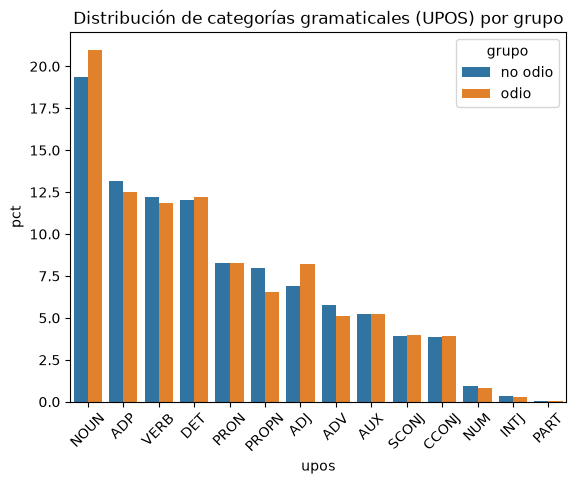

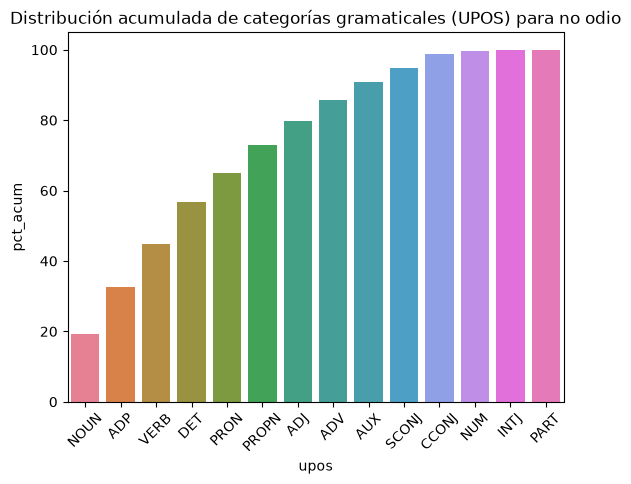

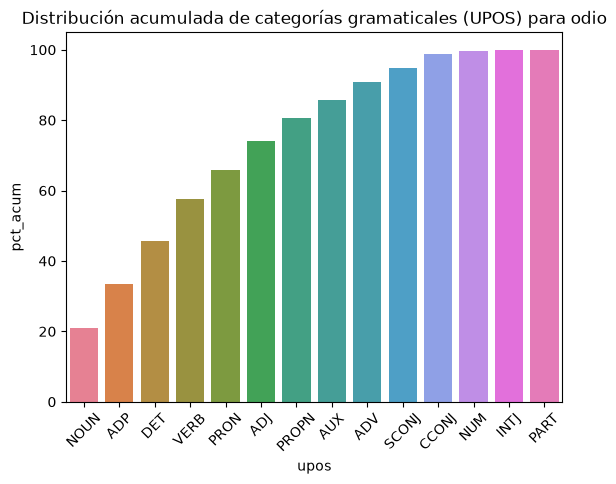

grupo,no odio,odio
upos,,
NOUN,19.34,20.99
ADP,13.15,12.52
VERB,12.20,11.83
DET,12.01,12.20
PRON,8.30,8.28
PROPN,7.99,6.53
ADJ,6.90,8.19
ADV,5.74,5.14
AUX,5.26,5.24


In [54]:
# Se excluyen las etiquetas que no son palabras
NO_PALABRA = {"PUNCT", "SPACE", "SYM", "X"}

grupos = {
    "no odio": comentarios[comentarios["INTENSIDAD"] == 0.0],
    "odio": comentarios[comentarios["INTENSIDAD"] > 0.0],
}

# creamos las filas del DataFrame (grupo, upos, count, pct)
filas = []
for grupo, df_grupo in grupos.items():
    upos_count = Counter()
    for doc in df_grupo["doc"]:
        upos_count.update(token.pos_ for token in doc if token.pos_ not in NO_PALABRA)

    # crear filas para cada grupo
    total = upos_count.total()
    filas.extend((grupo, upos, n, n / total * 100) for upos, n in upos_count.most_common())

df_upos = pd.DataFrame(filas, columns=["grupo", "upos", "count", "pct"])
df_upos["pct_acum"] = df_upos.groupby("grupo")["pct"].cumsum()

# frecuencia por grupo (mismo orden de categorías en ambos grupos)
orden = df_upos.loc[df_upos["grupo"] == "no odio", "upos"]
sns.barplot(data=df_upos, x="upos", y="pct", hue="grupo", order=orden)
plt.xticks(rotation=45)
plt.title("Distribución de categorías gramaticales (UPOS) por grupo")
plt.show()

# frecuencia acumulada grupo no_odio
sns.barplot(data=df_upos[df_upos["grupo"] == "no odio"], x="upos", y="pct_acum", hue="upos")
plt.title("Distribución acumulada de categorías gramaticales (UPOS) para no odio")
plt.xticks(rotation=45)
plt.show()

# frecuencia acumulada grupo no_odio
sns.barplot(data=df_upos[df_upos["grupo"] == "odio"], x="upos", y="pct_acum", hue="upos")
plt.title("Distribución acumulada de categorías gramaticales (UPOS) para odio")
plt.xticks(rotation=45)
plt.show()

(
    df_upos.pivot(index="upos", columns="grupo", values="pct")
    .sort_values("no odio", ascending=False)
    .round(2)
)

<b>Incluye aquí, debajo de la línea, la explicación de la característica propuesta y su motivación. Incluye también una explicación del código fuente aportado.</b>
<hr>
Esta característica mide la frecuencia de cada categoría gramatical (UPOS) de las palabras de los comentarios, por separado para los grupos odio y no odio. Describe el estilo con el que se construye el mensaje: un texto con muchos sustantivos y preposiciones es más descriptivo, mientras que uno con más verbos y sutantivos puede ser uno más imperativo. Si la mezcla de categorías difiere entre grupos, puede servir como rasgo para un clasificador. Por ejemplo, una receta podría contener mayor cantidad de verbos (por ser imperativa) que una novela (por ser descriptiva).

En el código, para cada grupo se cuenta cada una de las categorías gramaticales UPOS (`token.pos_`) con un `Counter`, excluyendo `PUNCT`, `SPACE`, `SYM` y `X` (no son palabras). Los conteos se normalizan por el total de cada grupo para poder compararlos, ya que, aunque los dos grupos tienen 10.618 comentarios, los de odio son más cortos y suman menos palabras. Las gráficas acumuladas ordenan las categorías de cada grupo por su propia frecuencia.

Resultados:
- En ambos grupos el sustantivo es la categoría más frecuente (19,3 % en no odio y 21,0 % en odio). Sustantivo, adposición, verbo y determinante concentran en torno al 57 % de las palabras en los dos grupos (56,7 % y 57,5 %).
- En odio hay más sustantivos (21,0 % frente a 19,3 %) y más adjetivos (8,2 % frente a 6,9 %). Una posible lectura es que en los comentarios con odio se hable negativamente de esos sustantivos, calificándolos con adjetivos (por ejemplo, para denigrar a un grupo o una idea). Es solo una hipótesis: la categoría gramatical no indica si el tono es negativo, y habría que revisar los comentarios concretos o aplicar un análisis de sentimiento para comprobarla.
- En no odio hay más nombres propios (8,0 % frente a 6,5 %) y algo más de adposiciones (13,2 % frente a 12,5 %) y de adverbios (5,7 % frente a 5,1 %).
- El resto de categorías (verbos, pronombres, determinantes, auxiliares, conjunciones, numerales e interjecciones) difieren en menos de 0,5 puntos.

La lectura que puede realizarse de esto es limitada, pues la diferencia de porcentaje para cada categoría es poca y podría deberse a características del conjunto específico seleccionado.

Limitaciones: los grupos son muestras de 10.618 comentarios (todos los comentarios con odio del corpus y los primeros 10.618 comentarios sin odio). Además, el etiquetador de `es_core_news_md` se equivoca más con texto de redes sociales.

**Referencias**

*Categorías gramaticales*
- [Atributos de Token (spaCy)](https://spacy.io/api/token#attributes): `pos_`, la categoría gramatical gruesa del conjunto Universal POS.
- [Part-of-speech tagging (spaCy)](https://spacy.io/usage/linguistic-features#pos-tagging): `pos_` como etiqueta UPOS simple.
- [Universal POS tags (Universal Dependencies)](https://universaldependencies.org/u/pos/): definición de las etiquetas UPOS, incluidas `PUNCT`, `SYM` y `X`.
- [Glosario de etiquetas de spaCy](https://github.com/explosion/spaCy/blob/master/spacy/glossary.py): incluye `SPACE` entre las etiquetas UPOS que usa spaCy para los tokens de espacio en blanco.

*Python y pandas*
- [collections.Counter](https://docs.python.org/3/library/collections.html#collections.Counter): `update`, `most_common` y `total` (este último desde Python 3.10).
- [DataFrameGroupBy.cumcount](https://pandas.pydata.org/docs/reference/api/pandas.api.typing.DataFrameGroupBy.cumcount.html): numeración de las categorías dentro de cada grupo (`rank`).
- [SeriesGroupBy.cumsum](https://pandas.pydata.org/docs/reference/api/pandas.api.typing.SeriesGroupBy.cumsum.html): frecuencia acumulada dentro de cada grupo (`pct_acum`).
- [DataFrame.pivot](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.pivot.html): tabla final con una columna por grupo.

*Visualización*
- [seaborn.barplot](https://seaborn.pydata.org/generated/seaborn.barplot.html): gráficos de barras; `order` fija el mismo orden de categorías en ambos grupos.


<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">Característica adicional 4.</span>


<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">Distancia semántica al centroide de cada grupo</span>

In [55]:
# Incluye aquí el código generado para poder responder a tu pregunta

# percentiles para describir cada distribución: p5, cuartiles (Q1, mediana, Q3) y p95
PERCENTILES = [0.5]

# negaciones que se conservan aunque spaCy las marque como stopwords
NEGACIONES = {
    "no", "ni", "nada", "nunca", "jamás", "tampoco", "sin",
    "nadie", "ningún", "ninguno", "ninguna", "ningunos", "ningunas",
}

# tratamientos de stopwords que se comparan: nombre -> criterio para conservar un token
FILTROS_STOPWORDS: dict[str, Callable[[Token], bool]] = {
    "con stopwords": lambda token: True,
    "con negaciones": lambda token: not token.is_stop or token.lower_ in NEGACIONES,
    "sin stopwords": lambda token: not token.is_stop,
}


def vector_contenido(doc: Doc, filtro: Callable[[Token], bool]) -> np.ndarray | None:
    """Vector de significado de un comentario a partir de sus palabras.

    Sustituye a `Doc.vector`, que promedia todos los tokens: aquí solo se promedian
    las palabras alfabéticas que tienen vector en el modelo y que cumplen `filtro`,
    que decide qué hacer con las stopwords (ver `FILTROS_STOPWORDS`).

    Parámetros:
        doc: comentario ya procesado por el pipeline de spaCy.
        filtro: función que recibe un token y devuelve True si se conserva.

    Devuelve:
        Vector de dimensión d con la media por dimensión de los vectores de esas
        palabras, o None si el comentario no contiene ninguna.
    """
    # un vector por palabra válida:
    #   - is_alpha descarta puntuación, números y espacios
    #   - has_vector descarta tokens sin vector (tendrían un vector de ceros)
    #   - filtro aplica el tratamiento de stopwords elegido
    filas = [
        np.array(token.vector, dtype=np.float64)
        for token in doc
        if token.is_alpha and token.has_vector and filtro(token)
    ]

    # sin palabras válidas no hay media posible (se comprueba antes de crear el array)
    if not filas:
        return None

    # matriz (n_palabras, d): una fila por palabra, una columna por dimensión
    vectores = np.array(filas)

    # media de cada columna (axis=0) -> vector de dimensión d
    return vectores.mean(axis=0)


def distancia_coseno(X: np.ndarray, C: np.ndarray) -> np.ndarray:
    """Distancia coseno fila a fila entre dos matrices de la misma forma.

    Calcula 1 - cos(X[i], C[i]) para cada fila i. Vale 0 si los vectores apuntan en la
    misma dirección, 1 si son ortogonales y hasta 2 si son opuestos.

    Parámetros:
        X: matriz (n, d) con un vector por fila.
        C: matriz (n, d) con el vector con el que se compara cada fila de X.

    Devuelve:
        Array de n distancias.
    """
    # similitud coseno de cada par de filas: producto escalar / (norma de X[i] * norma de C[i])
    sim = (X * C).sum(axis=1) / (np.linalg.norm(X, axis=1) * np.linalg.norm(C, axis=1))

    # de similitud a distancia
    return 1 - sim


def centroide_por_fila(X: np.ndarray, mask: np.ndarray) -> np.ndarray:
    """Centroide de un grupo, calculado para cada fila de X.

    El centroide es la media por dimensión de los vectores del grupo marcado por `mask`.
    Si una fila pertenece al grupo, se excluye de su propio centroide (leave-one-out)
    para no acercarla artificialmente a él.

    Parámetros:
        X: matriz (n, d) con el vector de cada comentario.
        mask: array booleano de n elementos; True para las filas del grupo.

    Devuelve:
        Matriz (n, d) donde la fila i es el centroide con el que comparar X[i].
    """
    # tamaño del grupo y suma de sus vectores (base para calcular la media)
    n = mask.sum()
    suma = X[mask].sum(axis=0)

    # mask[:, None] convierte la máscara en columna (n, 1) para aplicarla fila a fila:
    #   - fila del grupo   -> media del grupo sin ella: (suma - X[i]) / (n - 1)
    #   - fila fuera de él -> media del grupo completo: suma / n
    return np.where(mask[:, None], (suma - X) / (n - 1), suma / n)

[con stopwords] comentarios descartados (sin palabras con vector): {'no odio': 192, 'odio': 153}
[con negaciones] comentarios descartados (sin palabras con vector): {'no odio': 411, 'odio': 235}
[sin stopwords] comentarios descartados (sin palabras con vector): {'no odio': 473, 'odio': 238}


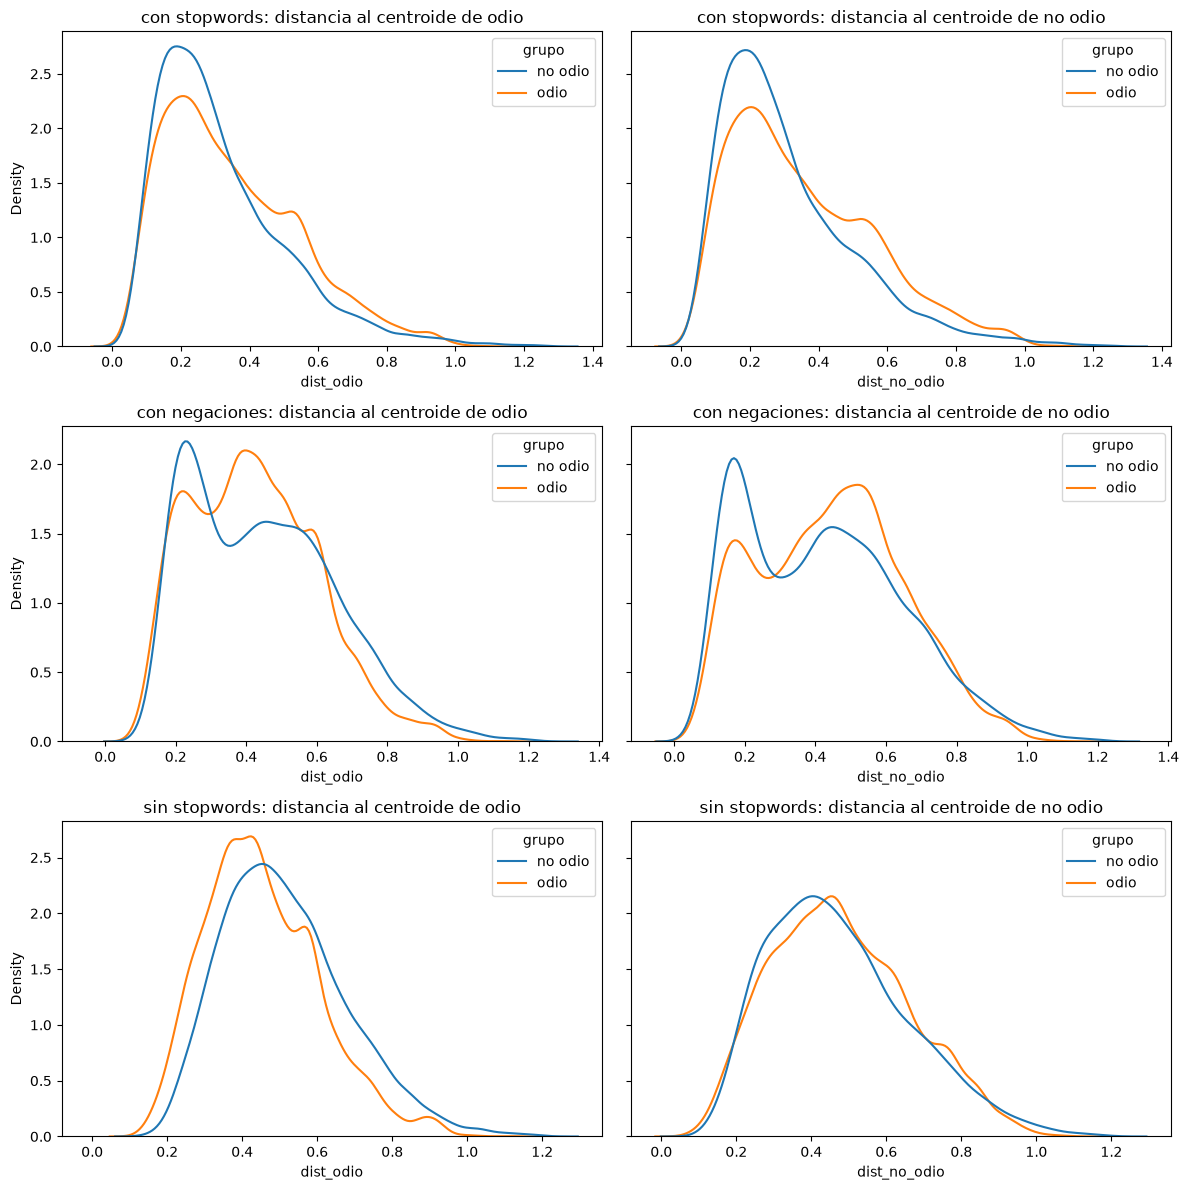

grupo                                       no odio        odio
stopwords      distancia    estadístico                        
con stopwords  dist_odio    count        10426.0000  10465.0000
                            mean             0.3186      0.3498
                            std              0.1881      0.1953
                            min              0.0374      0.0312
                            50%              0.2715      0.3110
                            max              1.2668      1.0975
               dist_no_odio count        10426.0000  10465.0000
                            mean             0.3114      0.3576
                            std              0.1957      0.2091
                            min              0.0275      0.0227
                            50%              0.2614      0.3140
                            max              1.2641      1.1183
con negaciones dist_odio    count        10207.0000  10383.0000
                            mean             0.4482      0.4224
                            std              0.2060      0.1788
                            min              0.0944      0.0812
                            50%              0.4316      0.4126
                            max              1.2418      1.1301
               dist_no_odio count        10207.0000  10383.0000
                            mean             0.4229      0.4443
                            std              0.2254      0.2046
                            min              0.0557      0.0426
                            50%              0.4132      0.4511
                            max              1.2104      1.1291
sin stopwords  dist_odio    count        10145.0000  10380.0000
                            mean             0.5144      0.4538
                            std              0.1664      0.1524
                            min              0.1400      0.1187
                            50%              0.4947      0.4353
                            max              1.2158      1.1109
               dist_no_odio count        10145.0000  10380.0000
                            mean             0.4750      0.4792
                            std              0.1881      0.1822
                            min              0.0878      0.0699
                            50%              0.4493      0.4607
                            max              1.2042      1.0899

In [56]:
# etiqueta de grupo de cada comentario
grupo = np.where(comentarios["INTENSIDAD"] > 0.0, "odio", "no odio")

# un análisis por cada tratamiento de stopwords: nombre -> DataFrame con las distancias
resultados: dict[str, pd.DataFrame] = {}
for nombre, filtro in FILTROS_STOPWORDS.items():
    # vector de contenido de cada comentario (None si no tiene palabras válidas)
    vectores = [vector_contenido(doc, filtro) for doc in comentarios["doc"]]
    tiene_vector = np.array([v is not None for v in vectores])

    # recuento de descartados por grupo
    descartados = pd.Series(~tiene_vector).groupby(grupo).sum()
    print(f"[{nombre}] comentarios descartados (sin palabras con vector): {descartados.to_dict()}")

    # solo los comentarios con vector; se conserva el índice de `comentarios` para poder cruzarlos
    df_vec = pd.DataFrame({"grupo": grupo[tiene_vector]}, index=comentarios.index[tiene_vector])

    # matriz (n_comentarios, d) con un vector por fila y máscara del grupo odio
    X = np.vstack([v for v in vectores if v is not None])
    es_odio = (df_vec["grupo"] == "odio").to_numpy()

    # distancia de cada comentario al centroide de odio y al de no odio
    df_vec["dist_odio"] = distancia_coseno(X, centroide_por_fila(X, es_odio))
    df_vec["dist_no_odio"] = distancia_coseno(X, centroide_por_fila(X, ~es_odio))
    resultados[nombre] = df_vec

# una fila de gráficas por tratamiento, con la distancia a cada centroide separada por grupo.
# common_norm=False normaliza cada curva por separado para comparar su forma
fig, axes = plt.subplots(len(resultados), 2, figsize=(12, 4 * len(resultados)), sharex="row", sharey="row")
for fila_axes, (nombre, df_vec) in zip(axes, resultados.items()):
    for ax, col, centroide in zip(fila_axes, ["dist_odio", "dist_no_odio"], ["odio", "no odio"]):
        sns.kdeplot(data=df_vec, x=col, hue="grupo", hue_order=["no odio", "odio"], common_norm=False, ax=ax)
        ax.set_title(f"{nombre}: distancia al centroide de {centroide}")
plt.tight_layout()
plt.show()

# estadísticos por tratamiento y grupo: count, media, desviación típica, mínimo, percentiles y máximo
pd.concat(
    {
        nombre: df_vec.groupby("grupo")[["dist_odio", "dist_no_odio"]]
        .describe(percentiles=PERCENTILES)
        .T
        for nombre, df_vec in resultados.items()
    },
    names=["stopwords", "distancia", "estadístico"],
).round(4)

<b>Incluye aquí, debajo de la línea, la explicación de la característica propuesta y su motivación. Incluye también una explicación del código fuente aportado.</b>
<hr>

**Qué mide y por qué**

Cada comentario se representa con un vector de significado: la media de los vectores de sus palabras con contenido. A partir de esos vectores se calcula el centroide de cada grupo (odio y no odio), es decir, su vector medio. La característica es la distancia coseno de cada comentario a cada uno de los dos centroides: cuanto menor es la distancia, más se parece el significado del comentario al significado medio de ese grupo.

El objetivo es comprobar si el significado agregado de un comentario permite distinguir a qué grupo pertenece. Si fuera así, los comentarios de odio estarían sistemáticamente más cerca del centroide de odio que los de no odio, y viceversa.

**Resultados**

Se comparan tres tratamientos de las stopwords al construir el vector de cada comentario: conservarlas todas, eliminarlas salvo las negaciones y eliminarlas todas. En cada caso se mide la distancia de cada comentario al centroide de odio y al de no odio.

Comentarios descartados por no contener ninguna palabra válida:

| Tratamiento | No odio | Odio |
|---|---|---|
| Con stopwords | 192 | 153 |
| Sin stopwords salvo negaciones | 411 | 235 |
| Sin stopwords | 473 | 238 |

Media (y mediana) de la distancia coseno de cada grupo a cada centroide:

| Tratamiento | Centroide | Comentarios de no odio | Comentarios de odio |
|---|---|---|---|
| Con stopwords | Odio | 0,319 (0,272) | 0,350 (0,311) |
| | No odio | 0,311 (0,261) | 0,358 (0,314) |
| Sin stopwords salvo negaciones | Odio | 0,448 (0,432) | 0,422 (0,413) |
| | No odio | 0,423 (0,413) | 0,444 (0,451) |
| Sin stopwords | Odio | 0,514 (0,495) | 0,454 (0,435) |
| | No odio | 0,475 (0,449) | 0,479 (0,461) |

Hallazgos:

1. **Las stopwords acercan todos los comentarios a ambos centroides.** Con stopwords, las distancias medias están entre 0,31 y 0,36, frente a 0,42–0,51 en los otros dos tratamientos. Las palabras funcionales son comunes a casi todos los comentarios, por lo que aproximan sus vectores entre sí y a los dos centroides.
2. **Con stopwords, los dos centroides apenas se distinguen.** Las gráficas de ambos centroides son prácticamente idénticas: cada comentario está casi a la misma distancia del centroide de odio que del de no odio. Además, en las dos gráficas los comentarios de odio están algo más lejos que los de no odio (media de 0,350 frente a 0,319 respecto al centroide de odio, y de 0,358 frente a 0,311 respecto al de no odio). Es decir, los comentarios de odio se alejan de ambos centroides, incluido el suyo.
3. **Sin stopwords salvo negaciones, cada grupo queda algo más cerca de su propio centroide.** Los comentarios de no odio están más cerca del centroide de no odio que los de odio (media de 0,423 frente a 0,444), y los de odio, más cerca del centroide de odio que los de no odio (0,422 frente a 0,448).
4. **Sin stopwords, la diferencia se concentra en la distancia al centroide de odio.** Los comentarios de odio están más cerca de ese centroide que los de no odio (media de 0,454 frente a 0,514; mediana de 0,435 frente a 0,495), y el desplazamiento se mantiene en todos los percentiles. En cambio, respecto al centroide de no odio, ambos grupos se sitúan a la misma distancia (media de 0,475 frente a 0,479), aunque se distingue que que medias están más cerca de sus grupos que del grupo contrario.
5. **En los tres tratamientos, las distribuciones de ambos grupos se solapan en gran parte.** La diferencia entre distribuciones no es significativa como para discriminar o clasificar en ninguno de los casos.

**Código**

Primero se definen dos constantes y tres funciones:

- **`NEGACIONES`**: conjunto de negaciones (`no`, `ni`, `nada`, `nunca`, `jamás`, `tampoco`, `sin`, `nadie`, `ningún`, `ninguno`, `ninguna`, `ningunos` y `ningunas`) que spaCy considera stopwords, pero que se quieren conservar en uno de los tratamientos porque invierten el sentido del comentario («odio a X» frente a «no odio a X»).
- **`FILTROS_STOPWORDS`**: diccionario con los tres tratamientos de stopwords que se comparan. Cada uno asocia un nombre a una función que recibe un token y decide si se conserva:
  - *Con stopwords*: se conservan todos los tokens.
  - *Sin stopwords salvo negaciones*: se eliminan las stopwords, salvo las que están en `NEGACIONES`.
  - *Sin stopwords*: se eliminan todas las stopwords.
- **`vector_contenido`**: construye el vector de significado de un comentario. Conserva los tokens alfabéticos que tienen vector en el modelo y que cumplen el filtro del tratamiento elegido, y devuelve la media de sus vectores. Si un comentario no contiene ninguna palabra válida, la función devuelve `None` y el comentario se descarta.
- **`distancia_coseno`**: calcula, fila a fila, la distancia coseno entre dos matrices $X$ y $C$:
$$
d(\vec{u}, \vec{v}) = 1 - \frac{\vec{u} \cdot \vec{v}}{\Vert\vec{u}\Vert \, \Vert\vec{v}\Vert}
$$
donde cada fila de $X$ es el vector de un comentario y la fila correspondiente de $C$ es el centroide con el que se compara. Vale 0 cuando ambos vectores apuntan en la misma dirección y aumenta a medida que sus direcciones se separan.
- **`centroide_por_fila`**: calcula el centroide de un grupo para cada comentario. Si el comentario pertenece a ese grupo, se excluye de la media (*leave-one-out*); si no pertenece, se usa la media del grupo completo. La exclusión es necesaria porque un vector incluido en la media la acerca a sí mismo, lo que reduciría artificialmente su distancia al centroide de su propio grupo.

A continuación, se repite el mismo análisis para cada uno de los tres tratamientos de stopwords:

1. Se calcula el vector de cada comentario con el filtro correspondiente, se descartan los que no tienen ninguna palabra válida y se muestra cuántos se descartan en cada grupo.
2. Con los vectores restantes se calcula la distancia de cada comentario al centroide de odio y al de no odio. Los resultados se guardan en `resultados`, un diccionario con un DataFrame por tratamiento que conserva el índice de `comentarios`.

Por último, se dibuja una fila de gráficas por tratamiento, con la distribución de la distancia a cada centroide separada por grupo, y se muestra una tabla con los estadísticos descriptivos de cada tratamiento y grupo: media, desviación típica, mínimo, mediana y máximo.

**Limitaciones**

- La media de vectores solo recoge qué palabras aparecen en el comentario y con qué frecuencia, no su orden. Por ejemplo, «odio al pp, pero amo al psoe» y «odio al psoe, pero amo al pp» obtienen exactamente el mismo vector.
- Al eliminar las stopwords también se eliminan las negaciones (`no`, `nunca`, `ni`, `sin`), por lo que «odio a X» y «no odio a X» obtienen el mismo vector.
- Los vectores de `es_core_news_md` son estáticos: cada palabra tiene un único vector, independientemente del contexto, por lo que el método no capta la ironía ni los distintos sentidos de una misma palabra. Por ejemplo, "banco" de peces y "banco" como institución tendrían el mismo vector pues son la misma palabra.
- Las palabras sin vector en el modelo (erratas, textos en catalán u otras palabras fuera del vocabulario) se descartan.

**Referencias**

*spaCy*
- [Doc.vector](https://spacy.io/api/doc#vector) y [Doc.similarity](https://spacy.io/api/doc#similarity): el vector de un `Doc` es, por defecto, la media de los vectores de sus tokens, y la similitud por defecto es el coseno.
- [Word vectors and semantic similarity](https://spacy.io/usage/linguistic-features#vectors-similarity): la media de vectores no tiene en cuenta el orden de las palabras, y los tokens sin vector tienen un vector de ceros.
- [Atributos de Token](https://spacy.io/api/token#attributes): `is_alpha`, `is_stop`, `has_vector` y `vector`.
- [Lista de stopwords del español en spaCy](https://github.com/explosion/spaCy/blob/master/spacy/lang/es/stop_words.py): incluye negaciones como `no`, `nunca`, `ni` y `sin`.

*NumPy*
- [numpy.mean](https://numpy.org/doc/stable/reference/generated/numpy.mean.html): media a lo largo de un eje (`axis=0`, una media por columna).
- [Glosario de NumPy: *axis* y *along an axis*](https://numpy.org/doc/stable/glossary.html)
- [numpy.vstack](https://numpy.org/doc/stable/reference/generated/numpy.vstack.html): apila los vectores de los comentarios como filas de una matriz.
- [numpy.where](https://numpy.org/doc/stable/reference/generated/numpy.where.html): elige el centroide con o sin exclusión según la máscara del grupo.
- [numpy.linalg.norm](https://numpy.org/doc/stable/reference/generated/numpy.linalg.norm.html): norma de cada fila (`axis=1`).

*Distancia coseno y centroide*
- [scipy.spatial.distance.cosine](https://docs.scipy.org/doc/scipy/reference/generated/scipy.spatial.distance.cosine.html): definición de la distancia coseno.

*pandas y seaborn*
- [DataFrame.describe](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.describe.html): estadísticos descriptivos y percentiles.
- [seaborn.kdeplot](https://seaborn.pydata.org/generated/seaborn.kdeplot.html): `common_norm=False` normaliza cada distribución por separado.


<span style="font-size: 16pt; font-weight: bold; color: #0098cd;">Reflexión final</span>

<span>Una de las utilidades de la caracterización de texto es que nos sirve como etapa de <i>feature-extraction</i> (extración de características) de cara a un posterior sistema de clasificación. Es pertinente, por tanto, reflexionar sobre la capacidad discriminatoria de cada una de las características extraídas. </span>

<span> Responde, para ello, a la siguiente pregunta.</span>

<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">Reflexión final.</span>
<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">¿Es posible utilizar alguna de las características extraídas en las preguntas anteriores para determinar si un mensaje contiene odio? Justifica tu respuesta con el análisis estadístico que consideres necesario.</span>

<b>Incluye aquí, debajo de la línea, la explicación de tu respuesta</b>
<hr>
 

En general, como se ha ido mostrando en la explicación de cada característica, ninguna de las características propuestas permite distinguir con claridad si un mensaje contiene odio o no, aunque la de las palabras más frecuentes es la que más se acerca.

Las palabras más frecuentes (característica 1) son la que más información aporta: en los comentarios de odio el top 10 incluye palabras con una connotación claramente negativa (*mierda*, *puta*, *asco*, *gentuza*, *panfleto*, *vergüenza* y *basura*) que no aparecen entre las más frecuentes de los comentarios sin odio. Aun así, no basta por sí sola: solo mira palabras sueltas, así que no entiende el contexto ("no es una mierda" contaría igual que un insulto) ni a quién va dirigido el comentario.

Los signos de exclamación e interrogación (característica 2) tampoco permiten clasificar. El porcentaje de comentarios con algún signo es incluso menor en los de odio (22,58 % frente a 26,26 %) y la media por comentario es casi igual (0,62 frente a 0,61). Solo la densidad por cada 100 palabras es mayor en odio (3,89 frente a 2,94, un 32 % más), y eso puede deberse en parte a que los comentarios de odio son más breves, de modo que un solo signo pesa más. Como mucho, serviría como rasgo complementario.

La frecuencia de las categorías gramaticales (característica 3) no aporta información útil para clasificar, porque apenas difiere entre ambos grupos. La única diferencia apreciable es la mayor proporción de sustantivos y adjetivos en los comentarios de odio. Sin embargo, tampoco sirve para clasificar: un texto breve de tipo poético, narrativo o descriptivo también contendría muchos sustantivos y adjetivos sin expresar odio.

La distancia semántica a los centroides de cada grupo (característica 4) tiene algo de señal, pero tampoco basta. Sin stopwords, los comentarios de odio están más cerca del centroide de odio que los de no odio (media de 0,454 frente a 0,514), pero respecto al centroide de no odio ambos grupos se sitúan a la misma distancia (0,479 frente a 0,475), y en los tres tratamientos de stopwords las distribuciones de ambos grupos se solapan en gran parte. Además, al ser una media de vectores estáticos, no recoge el orden de las palabras, el contexto ni las negaciones, que son justamente lo que cambia el sentido de un comentario.

En mi opinión, varios de estos problemas se deben a que los métodos utilizados no tienen en cuenta el contexto ni tratan el lenguaje como una secuencia, algo que sí harían los modelos secuenciales, como las cadenas de Márkov o los mecanismos de atención. Representar un comentario solo mediante las palabras que contiene, sin su contexto ni su orden, dice poco sobre si expresa odio. Por ejemplo, en «me dijeron que Manolo piensa que es un asco el gobierno», ¿expresa odio quien escribe el comentario? No: el odio, en todo caso, es de Manolo.

Además, la forma de expresarse es muy personal, por lo que, salvo en los casos más claros, detectar el odio es difícil incluso para una persona. Por ejemplo, el comentario «eres un cabrón» no tiene contexto suficiente para identificar su tono, algo que sí sería posible en el habla gracias a la entonación. Aun así, incluso en ese caso, a una persona le puede costar determinarlo debido a la variedad de tonos en los que se puede expresar. Y todo ello sin tener en cuenta las diferencias culturales entre países.

Por último, el análisis tiene dos limitaciones importantes relacionadas con los datos:

- **La calidad del dataset.** Muchos comentarios están escritos en catalán, por lo que spaCy no puede analizarlos con precisión con un modelo entrenado para el español.
- **La selección de la muestra.** El grupo de no odio está formado por los primeros comentarios sin odio del CSV, no por una muestra aleatoria. Si el archivo está ordenado, por ejemplo por medio o por fecha, ese grupo puede proceder de unos pocos medios y no ser representativo del conjunto de comentarios sin odio. En ese caso, parte de las diferencias observadas entre los grupos podría deberse a la selección de la muestra y no a la presencia de odio.

Como mejoras, se propone detectar y eliminar los textos en catalán antes del análisis y seleccionar el grupo de no odio mediante un muestreo aleatorio con una semilla fija, para que sea representativo y reproducible.